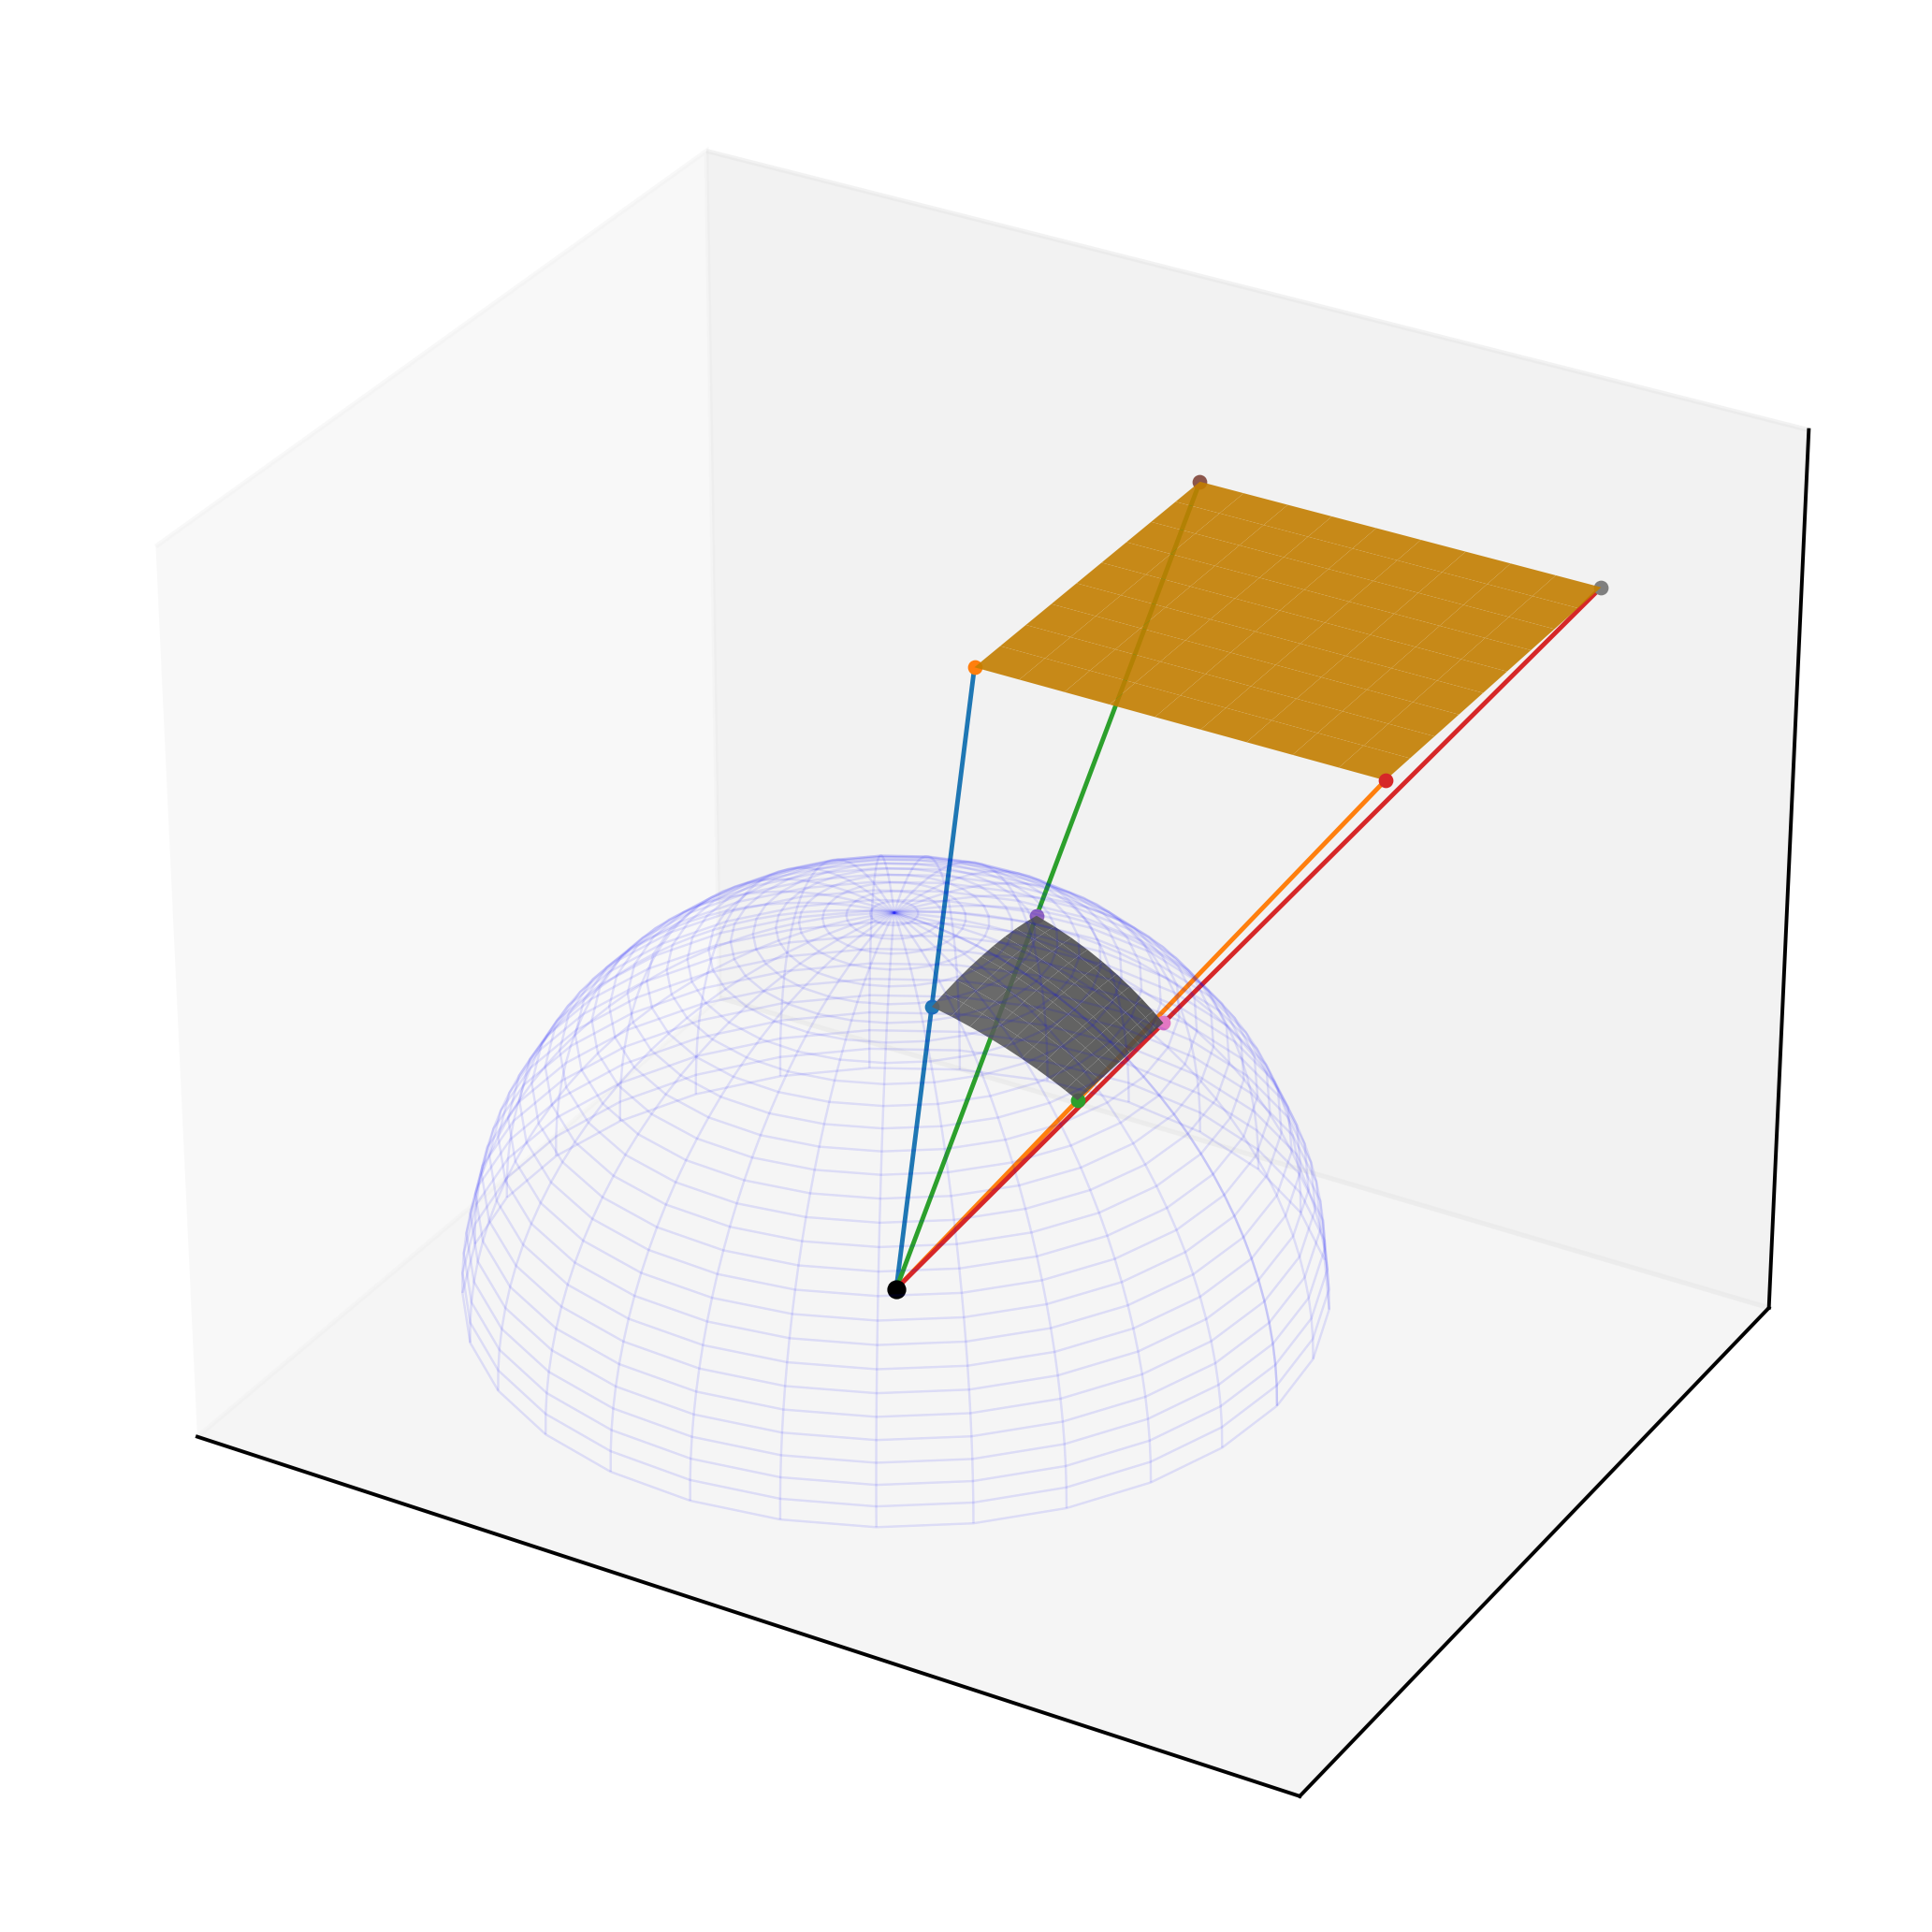

In [144]:
# render_gnomonic.py  (run once, outputs gnomonic.svg)
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(6, 6), dpi=350)
ax = fig.add_subplot(projection="3d")



RADIUS = 0.5
PLANE_WIDTH = 0.5

u = np.linspace(0, 2 * np.pi, 30)
v = np.linspace(0, np.pi / 2, 30)
xs = np.outer(RADIUS * np.cos(u), np.sin(v))
ys = np.outer(RADIUS * np.sin(u), np.sin(v))
zs = np.outer(np.ones(np.size(u)),RADIUS * np.cos(v))
ax.plot_wireframe(xs, ys, zs, color="blue", alpha=0.1, linewidth=0.5)
# ax.computed_zorder=False

def plane_fn(X, Y):

    P = np.array([0,0,1])
    NORMAL = np.array([0, 0, -1])

    x_component = P[0] * NORMAL[0] * np.ones_like(X) - NORMAL[0] * X
    y_component = P[1] * NORMAL[1] * np.ones_like(Y) - NORMAL[1] * Y

    return (x_component + y_component + P[2] * NORMAL[2] * np.ones_like(X)) / NORMAL[2]

px = np.linspace(.5 + -PLANE_WIDTH/2, .5+ PLANE_WIDTH/2, 10)
py = np.linspace(-PLANE_WIDTH/2, PLANE_WIDTH/2, 10)
PX, PY = np.meshgrid(px, py)
# PZ = np.ones_like(PX) * 3.0
PZ = plane_fn(PX, PY)

ax.plot_surface(
    PX, PY, PZ, color="orange", alpha=0.9
)


plane_points = np.stack([PX, PY, PZ], axis=-1).reshape(-1, 3)

patch_xs = []
patch_ys = []
patch_zs = []


for p in plane_points:

    pp = p / np.linalg.norm(p) * RADIUS

    patch_xs.append(pp[0])
    patch_ys.append(pp[1])
    patch_zs.append(pp[2])

grid_shape = PX.shape  # (3, 3) in your case
SX = np.array(patch_xs).reshape(grid_shape)
SY = np.array(patch_ys).reshape(grid_shape)
SZ = np.array(patch_zs).reshape(grid_shape)

ax.plot_surface(SX, SY, SZ, color="gray", alpha=0.9)

coarse_x = np.linspace(.5+ -PLANE_WIDTH/2, .5+ PLANE_WIDTH/2, 2)
coarse_y = np.linspace(-PLANE_WIDTH/2, PLANE_WIDTH/2, 2)

coarse_x, coarse_y = np.meshgrid(coarse_x, coarse_y)

plane_coarse_z = plane_fn(coarse_x, coarse_y)

plane_coarse_points = np.stack([coarse_x, coarse_y, plane_coarse_z], axis=-1).reshape(-1, 3)
for p in plane_coarse_points:

    pp = p / np.linalg.norm(p) * RADIUS
    ax.scatter3D([pp[0]], [pp[1]], [pp[2]], s=5)
    ax.plot([0, p[0]], [0, p[1]], [0, p[2]], linewidth=1)
    ax.scatter3D([p[0]], [p[1]], [p[2]], s=5)


# ax.quiver(0,0,0, ())

ax.scatter([0], [0], [0], color="black", s=10, zorder=5)

ax.set_box_aspect([1, 1, 1])
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.set_zticks([])
plt.tight_layout()
plt.savefig("gnomonic.svg", format="svg", bbox_inches="tight")



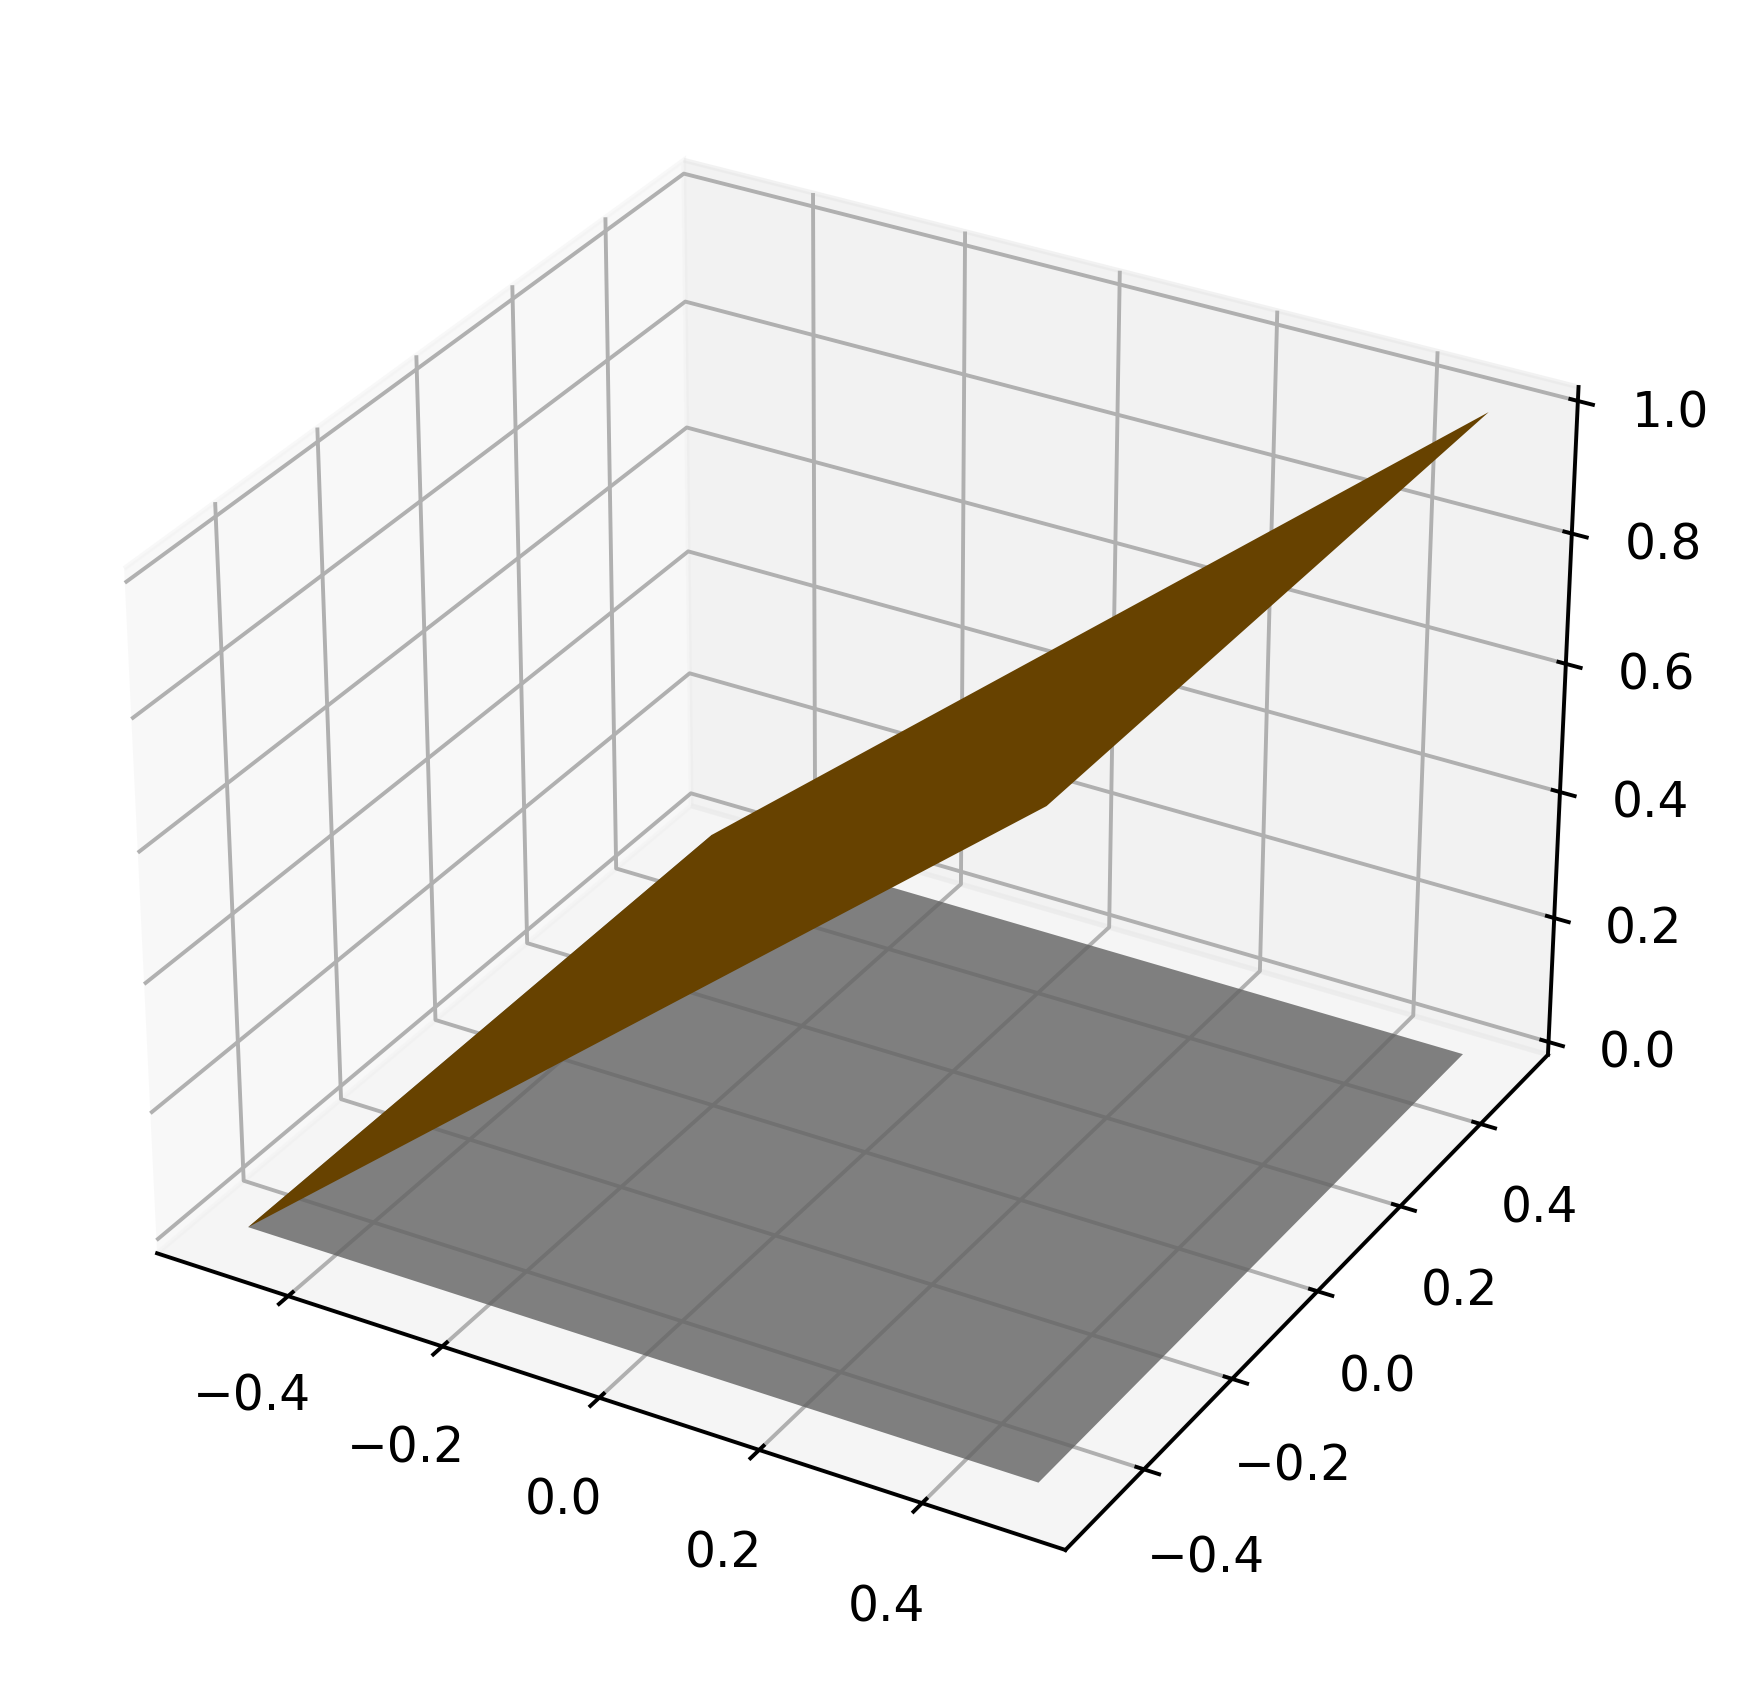

In [133]:
fig = plt.figure(figsize=(6,6), dpi=350)
ax = fig.add_subplot(111,projection="3d")

x = np.linspace(-.5, .5, 2)
y = np.linspace(-.5, .5, 2)

x, y = np.meshgrid(x,y)
z = np.zeros_like(x)


ax.plot_surface(x, y, z, color="gray", alpha=0.8)

ax.plot_surface(y, x, y + 0.5 * np.ones_like(x), color="orange", shade=True)




